# Regional Poverty

How do county poverty percentages vary across states?

Data: [ggplot2/midwest](https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/midwest.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Means weight counties equally, not people; historical county aggregates cannot describe individuals.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Regional Poverty',
 'executed_utc': '2026-11-21T10:14:09.791038+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/ggplot2/midwest.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/midwest.html',
 'sha256': '08baf8ae6cc820a2397fad11e7bd1c8fc49726bccb18c393af82566ad71b3a04',
 'raw_rows': 437,
 'analysis_rows': 437,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,437
1,PID,int64,0,0.0,437
2,county,object,0,0.0,320
3,state,object,0,0.0,5
4,area,float64,0,0.0,70
5,poptotal,int64,0,0.0,435
6,popdensity,float64,0,0.0,436
7,popwhite,int64,0,0.0,437
8,popblack,int64,0,0.0,306
9,popamerindian,int64,0,0.0,271


## SQL and analysis
Complete-case descriptive comparison of percbelowpoverty by state; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "state" AS segment, COUNT(*) AS rows_used, AVG("percbelowpoverty") AS metric, MIN("percbelowpoverty") AS minimum, MAX("percbelowpoverty") AS maximum FROM observations GROUP BY "state" ORDER BY "state";

The largest observed mean percbelowpoverty is 14.225 for MI. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,IL,102,13.076446,2.714734,32.244278
1,IN,92,10.318443,3.591644,19.439019
2,MI,83,14.224789,4.131044,26.409920
3,OH,88,13.033071,4.897294,28.673385
4,WI,72,11.894845,2.180168,48.691099


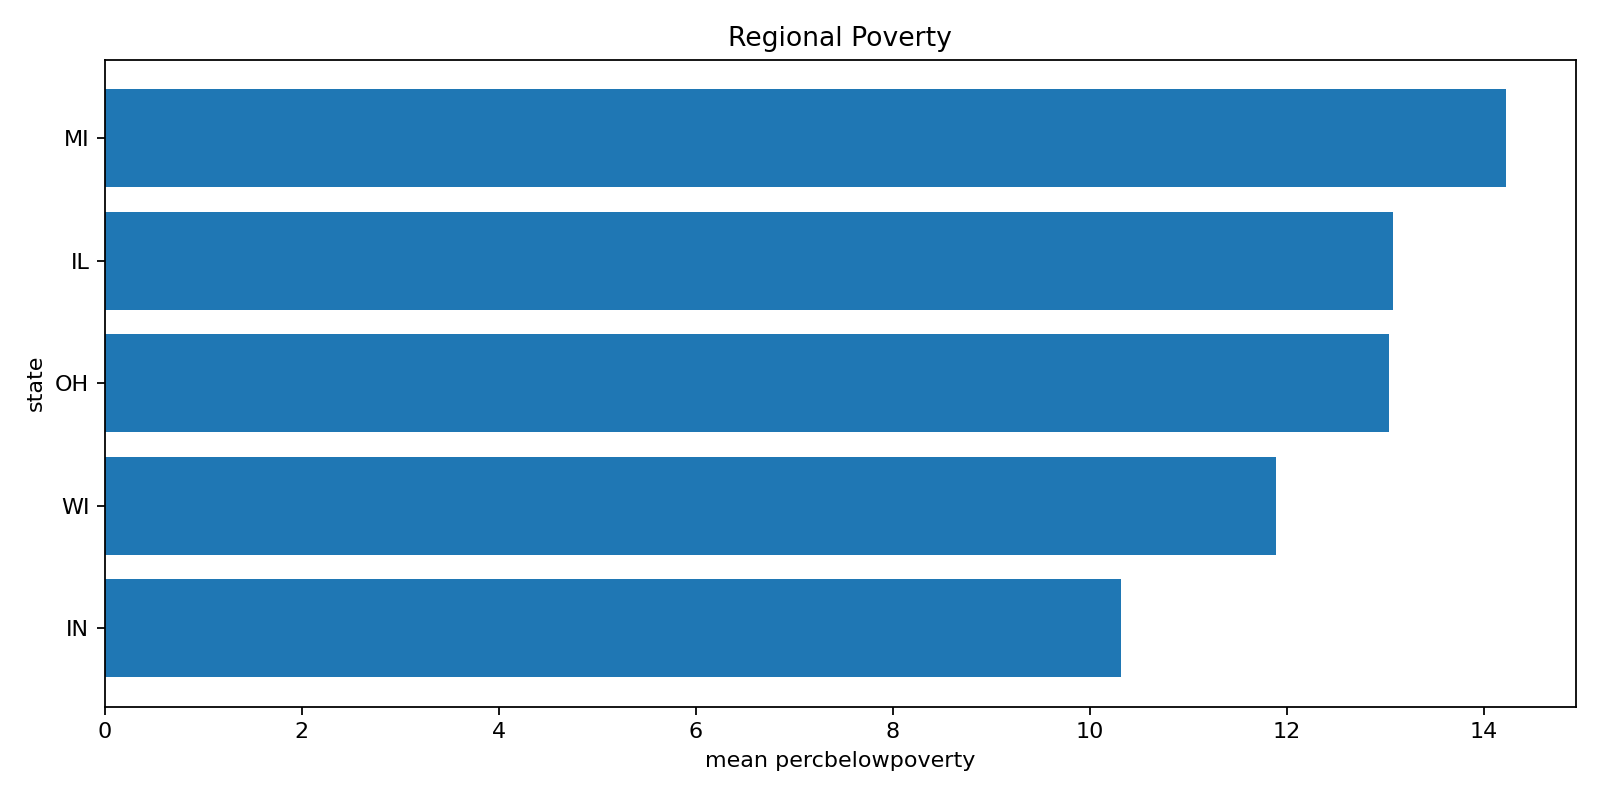

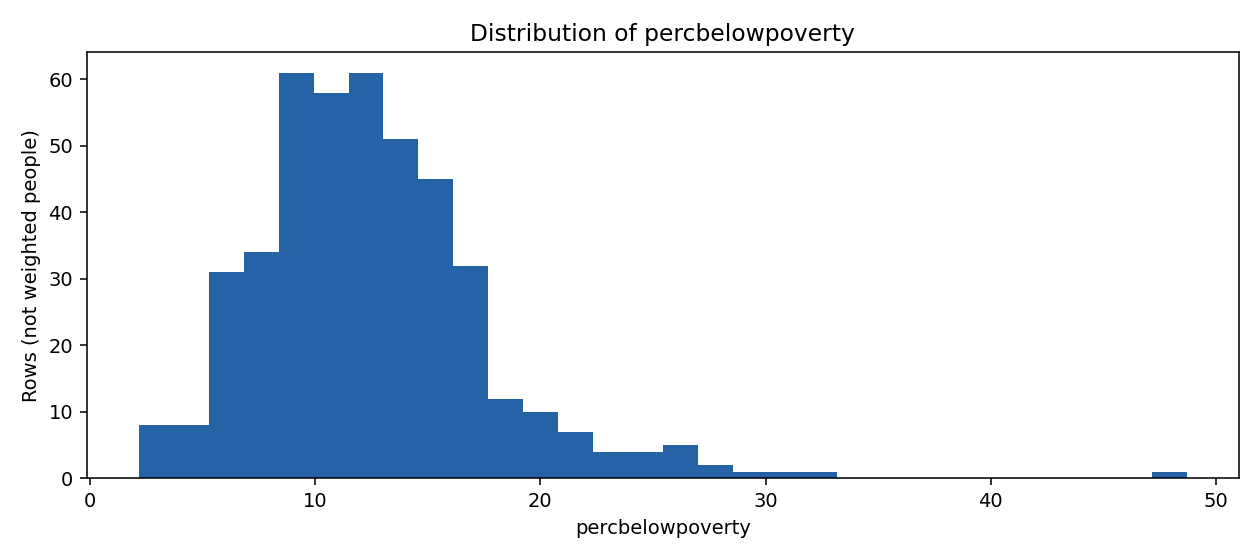

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Means weight counties equally, not people; historical county aggregates cannot describe individuals.

**Next action:** Recalculate population-weighted estimates using the correct poverty denominator.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.